# Titanic ML Lab — Exploratory Analysis Notebook

A reproducible, code-first companion to the app. It uses the same `src/` modules as the Streamlit pages, so every number matches the app. Run from the project root or the `notebooks/` folder.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'src').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src import data_loader, eda
from src.data_validation import validate_dataframe
sns.set_theme(style='whitegrid', palette=['#3a8ee6', '#e8693a', '#1fa883'])
pd.set_option('display.width', 140)

## 1. Load and validate

In [2]:
train, test = data_loader.load_train(), data_loader.load_test()
for kind, df in (('train', train), ('test', test)):
    rep = validate_dataframe(df, kind)
    st = data_loader.dataset_status(kind)
    print(f'{kind}: {df.shape}, valid={rep.is_valid}, official Kaggle checksum={st.is_official}')
train.head()

train: (891, 12), valid=True, official Kaggle checksum=True
test: (418, 11), valid=True, official Kaggle checksum=True


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
eda.overview(train) | {'dtypes': None}

{'passengers': 891,
 'survivors': 342,
 'non_survivors': 549,
 'survival_rate': 0.3838383838383838,
 'features': 11,
 'missing_cells': 866,
 'missing_pct': 8.099513655069211,
 'duplicates': 0,
 'dtypes': None}

In [4]:
eda.missing_table(train)

,column,missing,missing_pct,strategy
0,Cabin,687,77.10,Not imputed — converted to 'CabinKnown' and 'D...
1,Age,177,19.87,Median per title group (learned on training fo...
2,Embarked,2,0.22,Most frequent port (learned on training folds)


## 2. Survival analysis

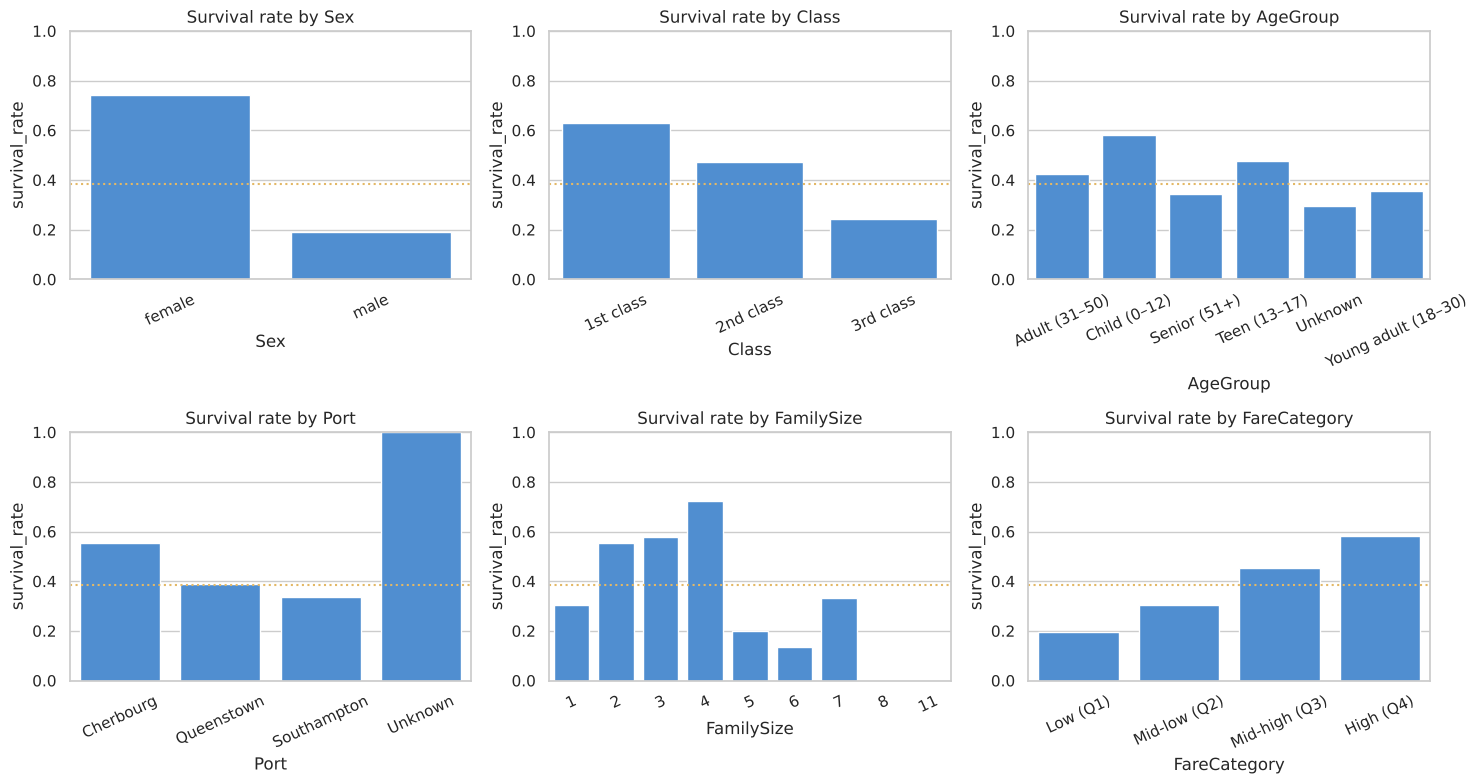

In [5]:
e = eda.enrich(train)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
specs = [('Sex', None), ('Class', ['1st class', '2nd class', '3rd class']), ('AgeGroup', None), ('Port', None), ('FamilySize', None), ('FareCategory', eda.FARE_ORDER)]
for ax, (col, order) in zip(axes.ravel(), specs):
    g = eda.survival_by(e, col, order=order)
    sns.barplot(data=g, x=col, y='survival_rate', ax=ax, color='#3a8ee6')
    ax.axhline(train.Survived.mean(), ls=':', color='#e3b866')
    ax.set_ylim(0, 1); ax.set_title(f'Survival rate by {col}'); ax.tick_params(axis='x', rotation=25)
plt.tight_layout()

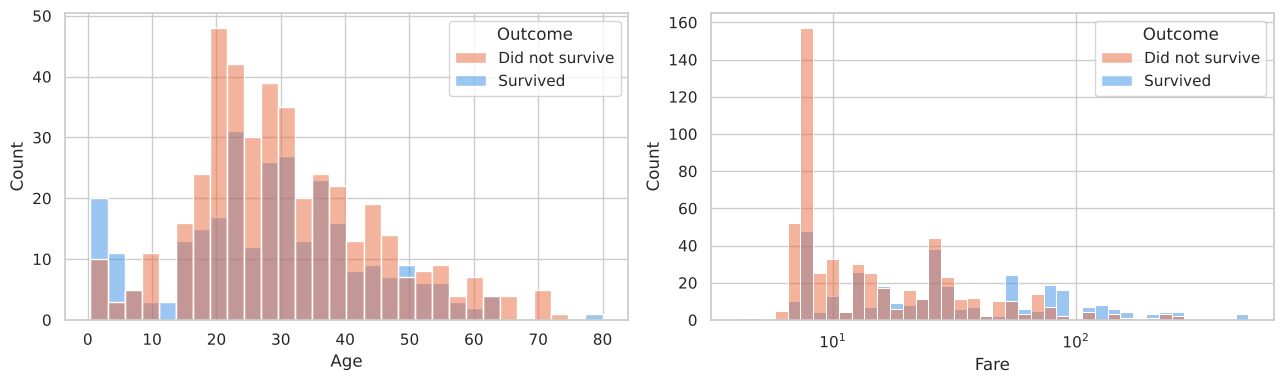

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=e, x='Age', hue='Outcome', bins=30, ax=axes[0], palette={'Survived': '#3a8ee6', 'Did not survive': '#e8693a'})
sns.histplot(data=e[e.Fare > 0], x='Fare', hue='Outcome', bins=40, log_scale=True, ax=axes[1], palette={'Survived': '#3a8ee6', 'Did not survive': '#e8693a'})
plt.tight_layout()

## 3. Correlations

Correlation measures linear association only — and is not causation.

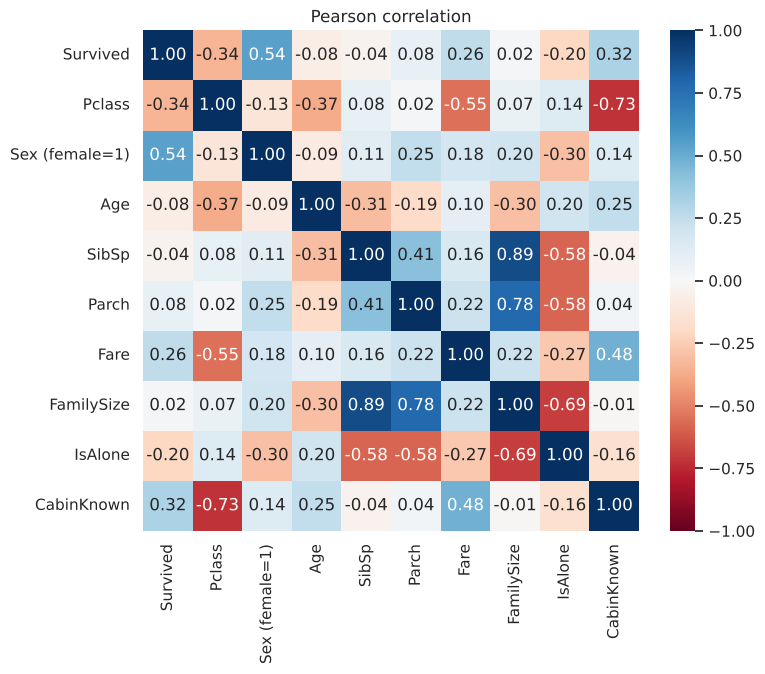

In [7]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(eda.correlation(train), annot=True, fmt='.2f', cmap='RdBu', center=0, vmin=-1, vmax=1)
plt.title('Pearson correlation');

## 4. Outliers — investigated, not removed

In [8]:
display(eda.outlier_report(train).round(2))
eda.extreme_passengers(train, 'Fare', 5)

,feature,min,q1,median,q3,max,iqr_low,iqr_high,iqr_outliers,z_gt_3,skew
0,Age,0.42,20.12,28.00,38.0,80.00,-6.69,64.81,11,2,0.39
1,Fare,0.00,7.91,14.45,31.0,512.33,-26.72,65.63,116,20,4.78
2,FamilySize,1.00,1.00,1.00,2.0,11.00,-0.50,3.50,91,25,2.72


,PassengerId,Name,Pclass,Sex,Age,FamilySize,Fare,Ticket,Survived
0,738,"Lesurer, Mr. Gustave J",1,male,35.0,1,512.3292,PC 17755,1
1,680,"Cardeza, Mr. Thomas Drake Martinez",1,male,36.0,2,512.3292,PC 17755,1
2,259,"Ward, Miss. Anna",1,female,35.0,1,512.3292,PC 17755,1
3,439,"Fortune, Mr. Mark",1,male,64.0,6,263.0000,19950,0
4,89,"Fortune, Miss. Mabel Helen",1,female,23.0,6,263.0000,19950,1


## 5. Automatic insights (computed, not hard-coded)

In [9]:
for i in eda.auto_insights(train):
    print('•', i['title'], '—', i['text'])

• Overall survival — 342 of 891 passengers in this dataset survived (38.4%).
• Sex was strongly associated with survival — Female passengers survived at 74.2% vs 18.9% for males (3.9× higher; χ² p = 1.2e-58).
• Survival differed between passenger classes — 1st class 63.0%, 2nd class 47.3%, 3rd class 24.2% (χ² p = 4.5e-23).
• Age contains predictive information — Children under 13 survived at 58.0% vs 38.1% for adults (age known for 80% of passengers).
• Family composition mattered — Small families (2–4) survived at 57.9%, people travelling alone at 30.4%, and large families (5+) at only 16.1%.
• Missing data can itself be informative — Passengers with a recorded cabin survived at 66.7% vs 30.0% without — cabin records were far more complete for 1st-class passengers.
• Embarkation port differed — Highest survival among passengers boarding at Cherbourg (55.4%), lowest at Southampton (33.7%). This mostly reflects the class mix at each port — a reminder that correlation is not causation.
•

## 6. Engineered features

In [10]:
from src.feature_engineering import TitanicFeatureEngineer
fe = TitanicFeatureEngineer().fit(train)
fe.transform(train).head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,TitleGroup,FarePerPerson,AgeGroup,FamilyCategory,CabinKnown,Deck,TicketGroupSize,AgeKnown
0,3,male,22.0,1,0,7.2500,S,2,0,Mr,3.62500,Young adult (18–30),Small family,0,Unknown,1.0,1
1,1,female,38.0,1,0,71.2833,C,2,0,Mrs,35.64165,Adult (31–50),Small family,1,C,1.0,1
2,3,female,26.0,0,0,7.9250,S,1,1,Miss,7.92500,Young adult (18–30),Alone,0,Unknown,1.0,1
3,1,female,35.0,1,0,53.1000,S,2,0,Mrs,26.55000,Adult (31–50),Small family,1,C,2.0,1
4,3,male,35.0,0,0,8.0500,S,1,1,Mr,8.05000,Adult (31–50),Alone,0,Unknown,1.0,1


## 7. Quick model check (5-fold CV on the development set)

The full, tuned comparison lives in `scripts/train_all.py` and the app's *Model Comparison* page.

In [11]:
from sklearn.model_selection import cross_val_score
from src.models import MODEL_ORDER, get_spec
from src.preprocessing import build_pipeline
from src.train import get_cv, split_data
X_dev, X_hold, y_dev, y_hold = split_data(train)
rows = []
for k in MODEL_ORDER:
    s = get_spec(k)
    pipe = build_pipeline(s.make(), scaler='standard' if s.scale_sensitive else 'none')
    sc = cross_val_score(pipe, X_dev, y_dev, cv=get_cv(), scoring='roc_auc', n_jobs=-1)
    rows.append({'model': s.name, 'cv_roc_auc_mean': sc.mean(), 'cv_roc_auc_std': sc.std()})
pd.DataFrame(rows).sort_values('cv_roc_auc_mean', ascending=False).round(4)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,model,cv_roc_auc_mean,cv_roc_auc_std
5,Gradient Boosting,0.8977,0.0215
6,XGBoost,0.8883,0.0179
2,Random Forest,0.8765,0.0183
4,Support Vector Machine,0.8727,0.0293
0,Logistic Regression,0.8696,0.0246
3,K-Nearest Neighbors,0.8509,0.0252
1,Decision Tree,0.7745,0.0149


## Takeaways

- Sex, class and title carry the strongest signal; family composition and age add some.
- Missingness (cabin, age) is informative and is encoded rather than hidden.
- All preprocessing is fitted inside the pipeline, per fold — no leakage.
- Predictions are statistical estimates from historical data, not facts about individuals.